## Chapter 4: Live Bayesian Optimization Loop

We now run 3 competing strategies against the REAL API, 30 steps each:
- Strategy A: EI-per-cost (weighted by how trustworthy each scale is)
- Strategy B: screen with bench, confirm with pilot
- Strategy Combined: A's logic early, switch to pilot-only confirmation late

We track "best pilot yield found so far" vs "cumulative EUR spent" for each,
so we can compare which strategy finds good recipes most cost-efficiently.

In [2]:
import numpy as np
import pandas as pd
import time
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.preprocessing import StandardScaler
from basic_client import BioreactorClient, USER, PASSWORD

params = ["T", "pH", "F1", "F2", "F3"]
lower_bounds = np.array([20.0, 3.0, 0.0, 0.0, 0.0])
upper_bounds = np.array([60.0, 9.5, 2.0, 2.0, 2.0])

fidelity_map = {"micro": 0, "bench": 1, "pilot": 2}
scale_cost = {"micro": 10, "bench": 500, "pilot": 2000}

# From Chapter 3's bias regression: how much do we trust each cheap scale?
# (R² of "does this scale's yield track pilot's yield")
scale_info_weight = {"micro": 0.739, "bench": 0.991, "pilot": 1.0}

client = BioreactorClient()
client.login(USER, PASSWORD)
print("Logged in successfully.")

# Start from everything we already collected in Chapter 1
data_pool = pd.read_csv("task1_2_data.csv")[["recipe_id", "scale", "T", "pH", "F1", "F2", "F3", "yield"]].copy()
next_recipe_id = data_pool["recipe_id"].max() + 1

print(f"Starting pool: {len(data_pool)} rows")

Logged in successfully.
Starting pool: 564 rows


### Helper 1: fit the multi-fidelity GP (Architecture A, the winner)

Same design as Chapter 3: one GP, fidelity as a 6th input, normalize_y=True
to avoid the zero-collapse bug we found earlier.

In [3]:
# ---------- fit_gp (noise bound widened) ----------
def fit_gp(data_pool):
    X = data_pool[params].copy()
    X["fidelity"] = data_pool["scale"].map(fidelity_map)
    y = data_pool["yield"].values

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X.values)

    noise_var_pilot = 0.0052 ** 2
    kernel = ConstantKernel(1.0) * RBF(length_scale=np.ones(6)) + \
             WhiteKernel(noise_level=noise_var_pilot, noise_level_bounds=(1e-6, 1.0))

    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42, normalize_y=True)
    gp.fit(X_scaled, y)
    return gp, scaler

bias_correction = {
    "micro": (0.094, 0.036),
    "bench": (1.151, 1.634),
    "pilot": (0.0, 1.0),
}

def predict_at_scale(gp, scaler, X_raw, scale):
    fid = fidelity_map[scale]
    X_with_fidelity = np.hstack([X_raw, np.full((len(X_raw), 1), fid)])
    X_scaled = scaler.transform(X_with_fidelity)
    mean, std = gp.predict(X_scaled, return_std=True)
    intercept, slope = bias_correction[scale]
    return intercept + slope * mean, slope * std

### Helper 2: Expected Improvement

Standard formula. y_best is the incumbent — the best REAL pilot
measurement seen so far. This is the exact spot your audit flagged:
y_best must ONLY come from real pilot rows, never from micro/bench,
or every scale's bias would corrupt the comparison.

In [4]:
from scipy.stats import norm

def expected_improvement(mean, std, y_best):
    std = np.maximum(std, 1e-9)  # avoid divide-by-zero
    z = (mean - y_best) / std
    ei = (mean - y_best) * norm.cdf(z) + std * norm.pdf(z)
    return ei

def get_incumbent(data_pool):
    pilot_rows = data_pool[data_pool["scale"] == "pilot"]
    return pilot_rows["yield"].max()

### Helper 3: candidate recipes

Every step, we generate a fresh batch of random candidate recipes and
score all of them — simplest way to search a 5D space without gradients.

In [5]:
def generate_candidates(data_pool, n_random=450, n_local=50):
    random_candidates = lower_bounds + np.random.rand(n_random, 5) * (upper_bounds - lower_bounds)
    best_row = data_pool.loc[data_pool["yield"].idxmax(), params].values.astype(float)
    noise = np.random.randn(n_local, 5) * (upper_bounds - lower_bounds) * 0.05
    local_candidates = np.clip(best_row + noise, lower_bounds, upper_bounds)
    return np.vstack([random_candidates, local_candidates])

### The main loop, one function for all 3 strategies

- "ei_per_cost": score every (candidate, scale) pair, pick the best ratio
- "screen_confirm": bench-only for the first `switch_step` steps, pilot-only after
- "combined": ei_per_cost for the first `switch_step` steps, pilot-only after

In [6]:
# ---------- main loop (per-scale EI, sqrt-cost weighting) ----------
def run_bo_loop(strategy, n_steps, data_pool, next_recipe_id, switch_fraction=0.7, force_pilot_every=3, save_path=None):
    data_pool = data_pool.copy()
    history = []
    switch_step = int(n_steps * switch_fraction)

    for step in range(n_steps):
        gp, scaler = fit_gp(data_pool)
        y_best = get_incumbent(data_pool)
        candidates = generate_candidates(data_pool)

        if strategy == "ei_per_cost":
            if (step + 1) % force_pilot_every == 0:
                # Forced check-in: confirm at pilot regardless of cost ranking
                chosen_scale = "pilot"
                mean_s, std_s = predict_at_scale(gp, scaler, candidates, "pilot")
                ei_s = expected_improvement(mean_s, std_s, y_best)
                chosen_x = candidates[np.argmax(ei_s)]
            else:
                best_score = -np.inf
                chosen_x, chosen_scale = None, None
                for scale in ["micro", "bench", "pilot"]:
                    mean_s, std_s = predict_at_scale(gp, scaler, candidates, scale)
                    ei_s = expected_improvement(mean_s, std_s, y_best)
                    score = ei_s * scale_info_weight[scale] / np.sqrt(scale_cost[scale])
                    idx = np.argmax(score)
                    if score[idx] > best_score:
                        best_score = score[idx]
                        chosen_x, chosen_scale = candidates[idx], scale

        elif strategy == "screen_confirm":
            chosen_scale = "bench" if step < switch_step else "pilot"
            mean_s, std_s = predict_at_scale(gp, scaler, candidates, chosen_scale)
            ei_s = expected_improvement(mean_s, std_s, y_best)
            chosen_x = candidates[np.argmax(ei_s)]

        elif strategy == "combined":
            if step < switch_step:
                best_score = -np.inf
                chosen_x, chosen_scale = None, None
                for scale in ["micro", "bench", "pilot"]:
                    mean_s, std_s = predict_at_scale(gp, scaler, candidates, scale)
                    ei_s = expected_improvement(mean_s, std_s, y_best)
                    score = ei_s * scale_info_weight[scale] / np.sqrt(scale_cost[scale])
                    idx = np.argmax(score)
                    if score[idx] > best_score:
                        best_score = score[idx]
                        chosen_x, chosen_scale = candidates[idx], scale
            else:
                chosen_scale = "pilot"
                mean_s, std_s = predict_at_scale(gp, scaler, candidates, "pilot")
                ei_s = expected_improvement(mean_s, std_s, y_best)
                chosen_x = candidates[np.argmax(ei_s)]
        else:
            raise ValueError("unknown strategy")

        result = client.run(
            scale=chosen_scale,
            T=chosen_x[0], pH=chosen_x[1], F1=chosen_x[2], F2=chosen_x[3], F3=chosen_x[4]
        )

        new_row = {
            "recipe_id": next_recipe_id, "scale": chosen_scale,
            "T": chosen_x[0], "pH": chosen_x[1], "F1": chosen_x[2], "F2": chosen_x[3], "F3": chosen_x[4],
            "yield": result["Y"]
        }
        data_pool = pd.concat([data_pool, pd.DataFrame([new_row])], ignore_index=True)
        next_recipe_id += 1

        incumbent_now = get_incumbent(data_pool)
        cost_so_far = (history[-1]["cumulative_cost"] + scale_cost[chosen_scale]) if history else scale_cost[chosen_scale]

        history.append({
            "step": step, "scale_queried": chosen_scale, "yield_observed": result["Y"],
            "incumbent": incumbent_now, "cumulative_cost": cost_so_far
        })

        print(f"[{strategy}] step {step+1}/{n_steps}: queried {chosen_scale:6s}, "
              f"yield={result['Y']:.3f}, best pilot so far={incumbent_now:.3f}, "
              f"total cost so far={cost_so_far}")

        time.sleep(0.2)
        if save_path:
            pd.DataFrame(history).to_csv(save_path, index=False)

    return pd.DataFrame(history), data_pool

### Run all 3 strategies

Each starts fresh from the same initial data pool, so the comparison is fair.
This is the part that actually spends live budget — feel free to run these
one cell at a time rather than all at once.

In [7]:
history_A, pool_A = run_bo_loop("ei_per_cost", n_steps=10, data_pool=data_pool,
                                  next_recipe_id=next_recipe_id, save_path="history_A.csv")

[ei_per_cost] step 1/10: queried bench , yield=23.011, best pilot so far=13.566, total cost so far=500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
[ei_per_cost] step 2/10: queried bench , yield=22.434, best pilot so far=13.566, total cost so far=1000
[ei_per_cost] step 3/10: queried pilot , yield=16.575, best pilot so far=16.575, total cost so far=3000
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
[ei_per_cost] step 4/10: queried bench , yield=21.627, best pilot so far=16.575, total cost so far=3500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
  [rate-limited, sleeping 39.1s]
  [rate-limited, sleeping 97.7s]
[ei_per_cost] step 5/10: queried bench , yield=7.816, best pilot so far=16.575, total cost so far=4000
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s

/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 4 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


[ei_per_cost] step 9/10: queried pilot , yield=12.390, best pilot so far=16.575, total cost so far=9000
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
[ei_per_cost] step 10/10: queried bench , yield=28.508, best pilot so far=16.575, total cost so far=9500


In [8]:
history_B, pool_B = run_bo_loop("screen_confirm", n_steps=10, data_pool=data_pool,
                                  next_recipe_id=next_recipe_id, save_path="history_B.csv")

  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
[screen_confirm] step 1/10: queried bench , yield=18.134, best pilot so far=13.566, total cost so far=500
[screen_confirm] step 2/10: queried bench , yield=27.684, best pilot so far=13.566, total cost so far=1000
[screen_confirm] step 3/10: queried bench , yield=27.664, best pilot so far=13.566, total cost so far=1500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
[screen_confirm] step 4/10: queried bench , yield=26.845, best pilot so far=13.566, total cost so far=2000
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
[screen_confirm] step 5/10: queried bench , yield=12.124, best pilot so far=13.566, total cost so far=2500
[screen_confirm] step 6/10: queried bench , yield=28.126, best pilot so far=13.566, total cost so far=3000
[screen_confirm] step 7/10: queried bench , yield=3.432, best pilot so far=13.566, total cost so far=3500
[screen_confirm] step 8/10: queried pilot , yield=1.138, best

In [9]:
history_combined, pool_combined = run_bo_loop("combined", n_steps=10, data_pool=data_pool,
                                                next_recipe_id=next_recipe_id, save_path="history_combined.csv")

[combined] step 1/10: queried bench , yield=21.399, best pilot so far=13.566, total cost so far=500
  [rate-limited, sleeping 1.0s]
[combined] step 2/10: queried bench , yield=25.043, best pilot so far=13.566, total cost so far=1000
[combined] step 3/10: queried bench , yield=23.451, best pilot so far=13.566, total cost so far=1500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
[combined] step 4/10: queried bench , yield=10.072, best pilot so far=13.566, total cost so far=2000
  [rate-limited, sleeping 1.0s]


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
[combined] step 5/10: queried bench , yield=26.508, best pilot so far=13.566, total cost so far=2500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
  [rate-limited, sleeping 15.6s]
[combined] step 6/10: queried bench , yield=27.006, best pilot so far=13.566, total cost so far=3000
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
[combined] step 7/10: queried bench , yield=32.157, best pilot so far=13.566, total cost so far=3500


/home/rushi/Projects/mlme_bioreactor/venv/lib/python3.10/site-packages/sklearn/gaussian_process/kernels.py:450: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


[combined] step 8/10: queried pilot , yield=11.079, best pilot so far=13.566, total cost so far=5500
  [rate-limited, sleeping 1.0s]
  [rate-limited, sleeping 2.5s]
  [rate-limited, sleeping 6.2s]
[combined] step 9/10: queried pilot , yield=18.462, best pilot so far=18.462, total cost so far=7500
[combined] step 10/10: queried pilot , yield=20.296, best pilot so far=20.296, total cost so far=9500


### Compare the 3 strategies

The key plot: best yield found so far, against how much EUR it cost to get there.
The strategy that reaches high yield fastest per euro spent wins.

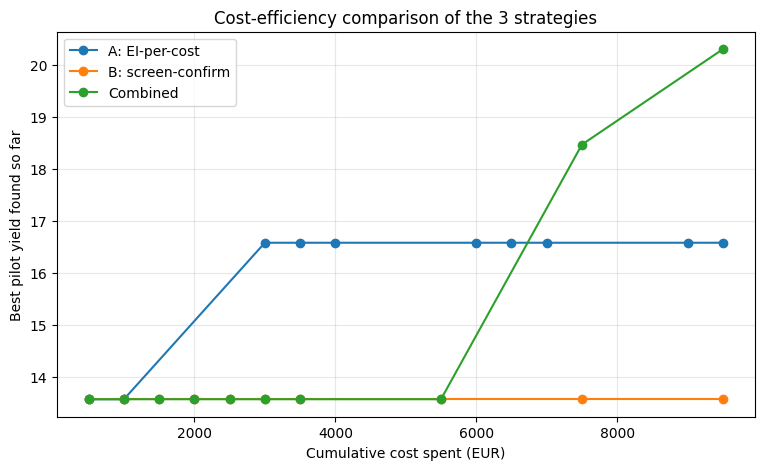

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for name, hist in [("A: EI-per-cost", history_A), ("B: screen-confirm", history_B), ("Combined", history_combined)]:
    plt.plot(hist["cumulative_cost"], hist["incumbent"], marker="o", label=name)

plt.xlabel("Cumulative cost spent (EUR)")
plt.ylabel("Best pilot yield found so far")
plt.title("Cost-efficiency comparison of the 3 strategies")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


## Chapter 5: Non-Adaptive Baseline (Sobol Random Search)

prove that - the BO loop is *actually learning*, not just spending
money. The only way to show that is to spend the **same EUR budget** on a
strategy with zero adaptivity — pure quasi-random sampling — and see if it
gets anywhere near as far.

Design choices, and why:
- **Same budget, not same step count.** Steps cost different amounts at
  different scales, so "10 steps" isn't a fair unit — EUR is. We match the
  budget one BO strategy actually spent (`history_A`'s final
  `cumulative_cost`), not the assignment's example figure of 15,000 EUR,
  since matching the real spend is what makes the comparison valid. Swap in
  a literal `15000` below if your assignment requires that exact number.
- **Same scale for every query.** The BO loop's "incumbent" is defined as
  the best *pilot* yield seen so far (see `get_incumbent`) — bench and micro
  results are cheaper but biased/noisier proxies. A random baseline that
  mixes scales wouldn't be measured on the same yardstick, so we spend the
  whole baseline budget on pilot-scale queries only.
- **Sobol, not `np.random.rand`.** Same reasoning as Chapter 1: Sobol points
  spread out evenly across the 5D space instead of clumping.

In [12]:
from scipy.stats import qmc

# ---- Budget: match what the BO loop actually spent ----
#BASELINE_BUDGET_EUR = history_A["cumulative_cost"].iloc[-1]

BASELINE_BUDGET_EUR = 15000.0

BASELINE_SCALE = "pilot"  # same scale the BO incumbent is judged on
cost_per_run = scale_cost[BASELINE_SCALE]
max_possible_steps = int(BASELINE_BUDGET_EUR // cost_per_run)

print(f"Baseline budget: {BASELINE_BUDGET_EUR:.0f} EUR -> up to "
      f"{max_possible_steps} pilot-scale runs at {cost_per_run} EUR each")

# Draw more Sobol points than we could possibly spend the budget on, so the
# loop below never runs out of candidates mid-way
sobol = qmc.Sobol(d=len(params), scramble=True, seed=7)
unit_points = sobol.random(max(64, max_possible_steps * 2))
baseline_candidates = qmc.scale(unit_points, lower_bounds, upper_bounds)

Baseline budget: 15000 EUR -> up to 7 pilot-scale runs at 2000 EUR each


### The baseline loop

No GP, no Expected Improvement — just take the next Sobol point, run it at
pilot scale, record it, repeat until the budget is gone. Same history
schema (`step`, `scale_queried`, `yield_observed`, `incumbent`,
`cumulative_cost`) as `run_bo_loop`, so it drops straight into the same
comparison plot.

In [13]:
def run_random_baseline(candidates, budget_eur, scale, data_pool, next_recipe_id, save_path=None):
    data_pool = data_pool.copy()
    history = []
    cumulative_cost = 0.0
    run_cost = scale_cost[scale]

    for step, x in enumerate(candidates):
        if cumulative_cost + run_cost > budget_eur:
            print(f"Stopping: next run ({run_cost} EUR) would exceed the "
                  f"{budget_eur:.0f} EUR budget (spent {cumulative_cost:.0f} so far).")
            break

        result = client.run(scale=scale, T=x[0], pH=x[1], F1=x[2], F2=x[3], F3=x[4])
        cumulative_cost += result.get("cost_eur", run_cost)

        new_row = {
            "recipe_id": next_recipe_id, "scale": scale,
            "T": x[0], "pH": x[1], "F1": x[2], "F2": x[3], "F3": x[4],
            "yield": result["Y"]
        }
        data_pool = pd.concat([data_pool, pd.DataFrame([new_row])], ignore_index=True)
        next_recipe_id += 1

        incumbent_now = data_pool[data_pool["scale"] == "pilot"]["yield"].max()

        history.append({
            "step": step, "scale_queried": scale, "yield_observed": result["Y"],
            "incumbent": incumbent_now, "cumulative_cost": cumulative_cost
        })

        print(f"[random baseline] step {step+1}: queried {scale:6s}, "
              f"yield={result['Y']:.3f}, best pilot so far={incumbent_now:.3f}, "
              f"total cost so far={cumulative_cost:.0f}")

        time.sleep(0.2)
        if save_path:
            pd.DataFrame(history).to_csv(save_path, index=False)

    return pd.DataFrame(history), data_pool


history_random, pool_random = run_random_baseline(
    baseline_candidates, budget_eur=BASELINE_BUDGET_EUR, scale=BASELINE_SCALE,
    data_pool=data_pool, next_recipe_id=next_recipe_id, save_path="history_random.csv"
)

[random baseline] step 1: queried pilot , yield=1.399, best pilot so far=13.566, total cost so far=2000
[random baseline] step 2: queried pilot , yield=3.439, best pilot so far=13.566, total cost so far=4000
[random baseline] step 3: queried pilot , yield=1.840, best pilot so far=13.566, total cost so far=6000
[random baseline] step 4: queried pilot , yield=1.053, best pilot so far=13.566, total cost so far=8000
[random baseline] step 5: queried pilot , yield=1.115, best pilot so far=13.566, total cost so far=10000
[random baseline] step 6: queried pilot , yield=1.715, best pilot so far=13.566, total cost so far=12000
[random baseline] step 7: queried pilot , yield=1.567, best pilot so far=13.566, total cost so far=14000
Stopping: next run (2000 EUR) would exceed the 15000 EUR budget (spent 14000 so far).


### Compare all strategies against the random baseline

The key plot: best yield found so far, against how much EUR it cost to get
there. If BO is doing its job, its curve should climb faster per euro and
land higher than the flat, lucky-or-unlucky random baseline.

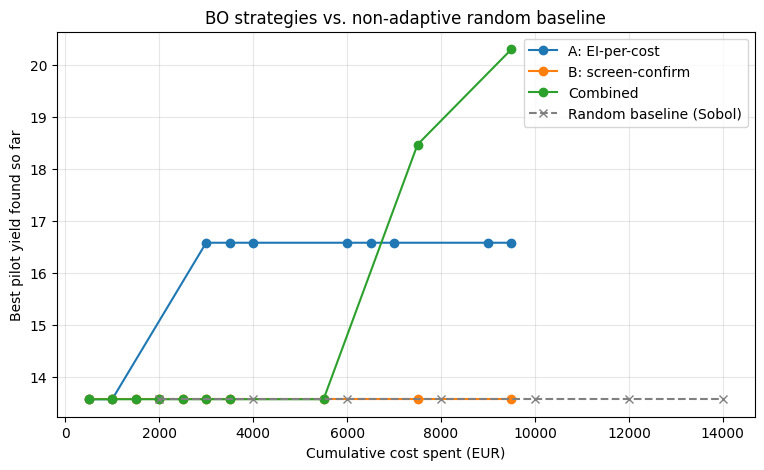

A: EI-per-cost      : 16.575 vs random 13.566  (+22.2%)
B: screen-confirm   : 13.566 vs random 13.566  (+0.0%)
Combined            : 20.296 vs random 13.566  (+49.6%)


In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for name, hist in [("A: EI-per-cost", history_A), ("B: screen-confirm", history_B),
                    ("Combined", history_combined), ("Random baseline (Sobol)", history_random)]:
    style = dict(marker="o") if name != "Random baseline (Sobol)" else dict(marker="x", linestyle="--", color="gray")
    plt.plot(hist["cumulative_cost"], hist["incumbent"], label=name, **style)

plt.xlabel("Cumulative cost spent (EUR)")
plt.ylabel("Best pilot yield found so far")
plt.title("BO strategies vs. non-adaptive random baseline")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

final_random = history_random["incumbent"].iloc[-1]
for name, hist in [("A: EI-per-cost", history_A), ("B: screen-confirm", history_B), ("Combined", history_combined)]:
    final_bo = hist["incumbent"].iloc[-1]
    lift = 100 * (final_bo - final_random) / final_random
    print(f"{name:20s}: {final_bo:6.3f} vs random {final_random:6.3f}  ({lift:+.1f}%)")